# 02 — Memory Traffic and Block-Size Tuning

**Goal:** change one kernel parameter at a time and record how the measured performance changes.

This notebook returns to vector addition because it is simple to reason about. It moves through a large array and does little arithmetic, so memory traffic and kernel-launch overhead are important. The bandwidth calculation below is an estimate; it is not a hardware-counter measurement.

## 1. Check the runtime

In [ ]:
import math
import statistics
import time
import torch
import triton
import triton.language as tl

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Google Colab, then run this notebook again.")

print("PyTorch:", torch.__version__)
print("Triton:", triton.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Triton: 3.6.0
GPU: Tesla T4


## 2. Kernel

Each program processes `BLOCK_SIZE` positions. A larger block means fewer programs are launched, but it does not guarantee faster execution. The compiler and GPU architecture also affect the result.

In [ ]:
@triton.jit
def vector_add_kernel(x_ptr, y_ptr, out_ptr, n_elements: tl.constexpr,
                      BLOCK_SIZE: tl.constexpr):
    pid = tl.program_id(0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements
    x = tl.load(x_ptr + offsets, mask=mask, other=0.0)
    y = tl.load(y_ptr + offsets, mask=mask, other=0.0)
    tl.store(out_ptr + offsets, x + y, mask=mask)


def launch_add(x, y, out, block_size):
    grid = (triton.cdiv(x.numel(), block_size),)
    vector_add_kernel[grid](x, y, out, x.numel(), BLOCK_SIZE=block_size)

## 3. Timing helper

We warm up each configuration before measuring it. Each reported result is the median of multiple rounds. That helps reduce random variation but does not remove all measurement error.

In [ ]:
def median_gpu_time_ms(fn, warmup=10, repeats=50, rounds=5):
    """Measure repeated calls with CUDA events; return median ms per call and all rounds."""
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize()

    samples = []
    for _ in range(rounds):
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)
        start.record()
        for _ in range(repeats):
            fn()
        end.record()
        end.synchronize()
        samples.append(start.elapsed_time(end) / repeats)

    return statistics.median(samples), samples

## 4. Run a controlled comparison

In [ ]:
N = 1 << 22
x = torch.randn(N, device="cuda", dtype=torch.float32)
y = torch.randn(N, device="cuda", dtype=torch.float32)
out = torch.empty_like(x)
block_sizes = [128, 256, 512, 1024, 2048]
results = []

for block_size in block_sizes:
    launch_add(x, y, out, block_size)
    torch.testing.assert_close(out, x + y)

    fn = lambda bs=block_size: launch_add(x, y, out, bs)
    ms, rounds = median_gpu_time_ms(fn, warmup=10, repeats=20, rounds=5)
    estimated_bytes = 3 * N * 4
    estimated_gb_s = estimated_bytes / (ms / 1000.0) / 1e9
    results.append((block_size, ms, estimated_gb_s))

print(f"{'BLOCK_SIZE':>12} {'median ms':>12} {'estimated GB/s':>16}")
for block_size, ms, gb_s in results:
    print(f"{block_size:>12} {ms:>12.6f} {gb_s:>16.2f}")

  BLOCK_SIZE    median ms   estimated GB/s
         128     0.197266           255.15
         256     0.199421           252.39
         512     0.207464           242.60
        1024     0.210328           239.30
        2048     0.210448           239.16


## 5. Plot the measurements

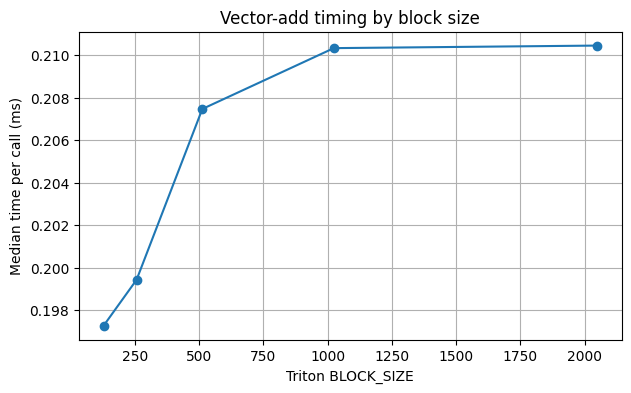

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot([r[0] for r in results], [r[1] for r in results], marker="o")
plt.xlabel("Triton BLOCK_SIZE")
plt.ylabel("Median time per call (ms)")
plt.title("Vector-add timing by block size")
plt.grid(True)
plt.show()

## 6. Interpret the result

There is no result that we should expect in advance. If the fastest setting changes between runs, record it and check the runtime conditions. This benchmark estimates bytes from the algorithm (two input reads and one output write per element); hardware caches may mean actual DRAM traffic is different.

For a portfolio, preserve the table, hardware/software versions, and a short explanation. Do not claim a universal best block size from one GPU.